### Que2.-
#### In this dataset you have to predict that whether we have to give ATTORNEY to the clients or not (0=Yes, 1=No) based on below factors.
#### CLMAGE - Age of Client
#### CLMSEX - Sex of client (0=Male, 1= Female)
#### SEATBELT - Whether client has Seatbelt or not (0=Yes, 1=No)
#### CLMINSUR - Whether Client give Insurance or not (0=Yes, 1=No)
#### LOSS - Loss that client faced

#### Prepare model by using logistic regression & Also calculate Accuracy by confusion matrix, Calculate accuracy score, precision score, recall score, f1 score.

#### Dataset : Claimants.csv


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("Claimants.csv")
df.head()

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0,0.0,1.0,0.0,50.0,34.940
1,1,1.0,0.0,0.0,18.0,0.891
2,1,0.0,1.0,0.0,5.0,0.330
3,0,0.0,1.0,1.0,31.0,0.037
4,1,0.0,1.0,0.0,30.0,0.038


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ATTORNEY  1340 non-null   int64  
 1   CLMSEX    1328 non-null   float64
 2   CLMINSUR  1299 non-null   float64
 3   SEATBELT  1292 non-null   float64
 4   CLMAGE    1151 non-null   float64
 5   LOSS      1340 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 62.9 KB


In [6]:
df.shape

(1340, 6)

In [7]:
df.isna().sum()

ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

In [8]:
df.dropna(inplace=True)

In [9]:
df.isna().sum()

ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

In [10]:
df.corr()

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
ATTORNEY,1.000000,0.097475,0.084609,-0.060795,0.001132,-0.225769
CLMSEX,0.097475,1.000000,0.058164,-0.017814,-0.017942,-0.029742
CLMINSUR,0.084609,0.058164,1.000000,0.021217,0.048166,0.019502
SEATBELT,-0.060795,-0.017814,0.021217,1.000000,-0.028343,0.131182
CLMAGE,0.001132,-0.017942,0.048166,-0.028343,1.000000,0.065513
LOSS,-0.225769,-0.029742,0.019502,0.131182,0.065513,1.000000


<Axes: >

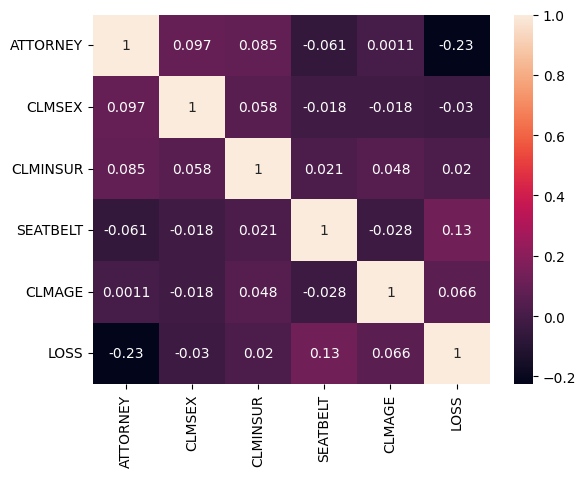

In [11]:
sns.heatmap(df.corr(),annot=True)

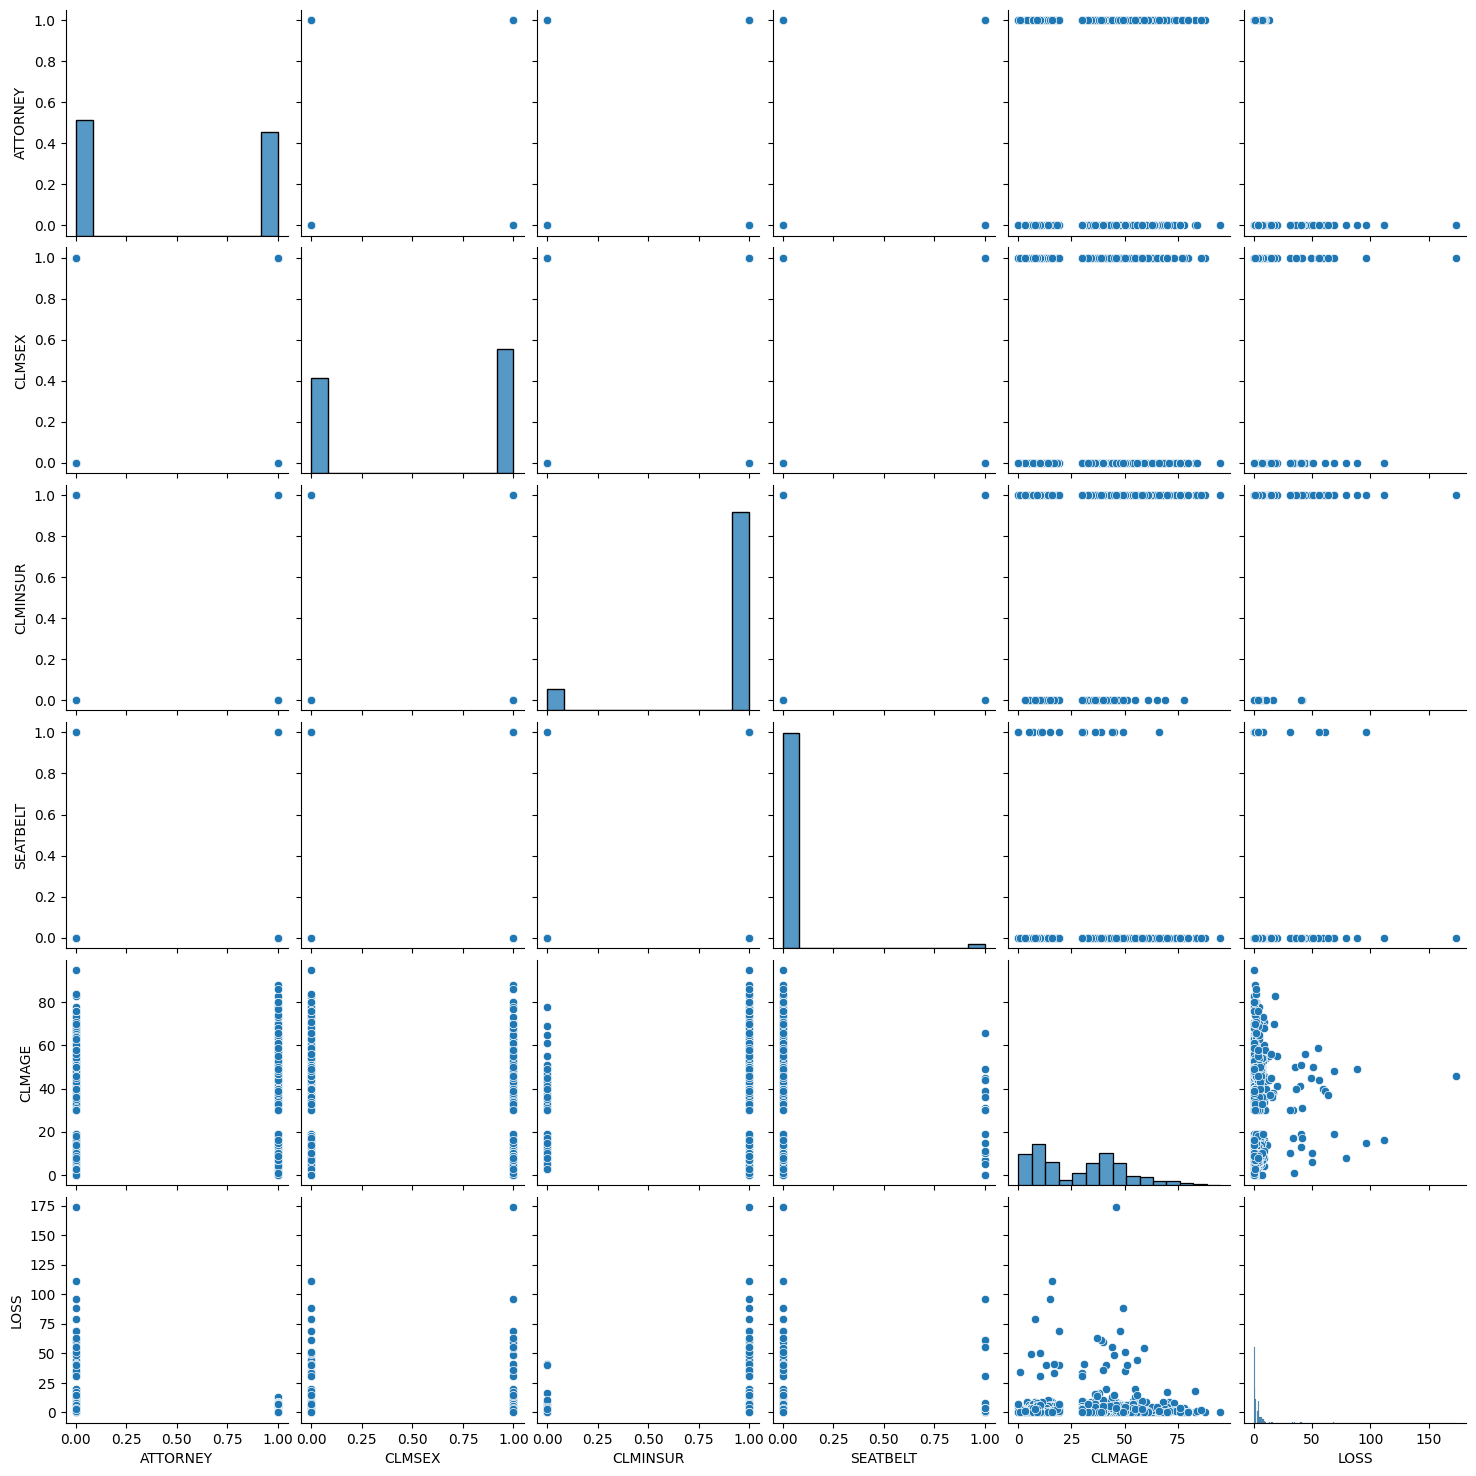

In [12]:
sns.pairplot(df)

In [13]:
X=df.drop('ATTORNEY',axis=1)
y=df['ATTORNEY']

In [14]:
df['ATTORNEY'].value_counts()

ATTORNEY
0    578
1    518
Name: count, dtype: int64

In [15]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.7,random_state=42)

In [17]:
from sklearn.linear_model import LogisticRegressionCV
model=LogisticRegressionCV()
model.fit(X_train,y_train)

LogisticRegressionCV()

In [18]:
y_pred=model.predict(X_test)

In [19]:
model.predict_proba(X_test)

array([[4.10890278e-01, 5.89109722e-01],
       [3.78719298e-01, 6.21280702e-01],
       [9.99999992e-01, 7.99922366e-09],
       [2.92949309e-01, 7.07050691e-01],
       [8.52185386e-01, 1.47814614e-01],
       [3.07711746e-01, 6.92288254e-01],
       [2.96398157e-01, 7.03601843e-01],
       [4.03389628e-01, 5.96610372e-01],
       [3.68133573e-01, 6.31866427e-01],
       [4.72324165e-01, 5.27675835e-01],
       [4.32737331e-01, 5.67262669e-01],
       [2.51758469e-01, 7.48241531e-01],
       [5.23213458e-01, 4.76786542e-01],
       [6.76536829e-01, 3.23463171e-01],
       [2.90801273e-01, 7.09198727e-01],
       [4.26965073e-01, 5.73034927e-01],
       [8.84193099e-01, 1.15806901e-01],
       [6.44094431e-01, 3.55905569e-01],
       [8.11713554e-01, 1.88286446e-01],
       [9.63272907e-01, 3.67270934e-02],
       [5.09825330e-01, 4.90174670e-01],
       [3.32712483e-01, 6.67287517e-01],
       [3.61859166e-01, 6.38140834e-01],
       [4.21827399e-01, 5.78172601e-01],
       [7.743798

In [20]:
from sklearn.metrics import confusion_matrix

matrix=confusion_matrix(y_test,y_pred)
matrix

array([[114,  58],
       [ 45, 112]], dtype=int64)

In [21]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import recall_score

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)

In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.72      0.66      0.69       172
           1       0.66      0.71      0.69       157

    accuracy                           0.69       329
   macro avg       0.69      0.69      0.69       329
weighted avg       0.69      0.69      0.69       329



In [23]:
print(f"Accuracy = {accuracy*100:.2f}%")
print(f"Precision = {precision*100:.2f}%")
print(f"F1-score= {f1*100:.2f}%")
print(f"recall= {recall*100:.2f}%")

Accuracy = 68.69%
Precision = 65.88%
F1-score= 68.50%
recall= 71.34%
